# Aula 03 - Detecção de áudio falso (ASVspoof 2019 LA)

Classificação de áudios em **bonafide** (fala legítima) ou **spoof** (fala sintetizada ou convertida por TTS/VC) usando features extraídas com a biblioteca pyAudioAnalysis e um SVM.

## 1. Configuração

As credenciais da API do Kaggle ficam nos *Secrets* do Colab (`KAGGLE_USERNAME` e `KAGGLE_KEY`).

In [17]:
!pip install -q pyAudioAnalysis eyed3 pydub hmmlearn imbalanced-learn plotly

import os

import pandas as pd
from google.colab import drive, userdata

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

drive.mount("/content/drive")

KAGGLE_DATASET = "awsaf49/asvpoof-2019-dataset"
PASTA_PROJETO = "/content/drive/MyDrive/pcs5917-aula03"
PASTA_AMOSTRAS = os.path.join(PASTA_PROJETO, "amostras")
SEMENTE = 42

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Dataset

Usamos a partição **LA (Logical Access)** do ASVspoof 2019 (Wang et al., 2020), em que os ataques são falas geradas por sistemas de síntese de voz (TTS) e conversão de voz (VC), obtida do Kaggle (`awsaf49/asvpoof-2019-dataset`).
O dataset (~25 GB) é baixado uma única vez para o disco do Colab, já que baixar arquivo por arquivo esbarra no limite de requisições da API do Kaggle, e só o conjunto de treino do LA e os protocolos são extraídos.
O protocolo de *countermeasure* (CM) indica, para cada áudio, o locutor, o ataque usado (`A01` a `A06`, ou `-` para fala legítima) e o rótulo (`bonafide` ou `spoof`).

In [18]:
PASTA_KAGGLE = "/content/kaggle"
ZIP_DATASET = os.path.join(PASTA_KAGGLE, "asvpoof-2019-dataset.zip")
RAIZ_LA = os.path.join(PASTA_KAGGLE, "LA", "LA")

if not os.path.isdir(os.path.join(RAIZ_LA, "ASVspoof2019_LA_train")):
    !kaggle datasets download -d {KAGGLE_DATASET} -p {PASTA_KAGGLE}
    !unzip -q {ZIP_DATASET} "LA/LA/ASVspoof2019_LA_train/*" "LA/LA/ASVspoof2019_LA_cm_protocols/*" -d {PASTA_KAGGLE}
    os.remove(ZIP_DATASET)

protocolo = pd.read_csv(
    os.path.join(RAIZ_LA, "ASVspoof2019_LA_cm_protocols", "ASVspoof2019.LA.cm.train.trn.txt"),
    sep=" ",
    header=None,
    names=["locutor", "arquivo", "_", "ataque", "rotulo"],
).drop(columns="_")

print(f"{len(protocolo)} áudios no conjunto de treino do LA")
protocolo.groupby(["rotulo", "ataque"]).size().rename("n").to_frame().T

25380 áudios no conjunto de treino do LA


rotulo bonafide spoof                              
ataque        -   A01   A02   A03   A04   A05   A06
n          2580  3800  3800  3800  3800  3800  3800

## 3. Subconjunto balanceado no Google Drive

O conjunto de treino é desbalanceado (2580 bonafide contra 22800 spoof).
O subconjunto tem 102 áudios de cada classe, e os spoof são divididos igualmente entre os 6 ataques (17 por ataque), para que nenhum sistema de TTS/VC domine a classe.
Os áudios ficam em `MyDrive/pcs5917-aula03/amostras/<rotulo>/` e os metadados em `amostras.csv`.

In [19]:
import shutil

N_POR_CLASSE = 102
ATAQUES = sorted(protocolo.loc[protocolo["rotulo"] == "spoof", "ataque"].unique())

embaralhado = protocolo.sample(frac=1, random_state=SEMENTE)
amostras = pd.concat(
    [
        embaralhado[embaralhado["rotulo"] == "bonafide"].head(N_POR_CLASSE),
        embaralhado[embaralhado["rotulo"] == "spoof"].groupby("ataque").head(N_POR_CLASSE // len(ATAQUES)),
    ],
    ignore_index=True,
)
amostras["caminho"] = [
    os.path.join(PASTA_AMOSTRAS, rotulo, f"{arquivo}.flac")
    for rotulo, arquivo in zip(amostras["rotulo"], amostras["arquivo"])
]

for arquivo, destino in zip(amostras["arquivo"], amostras["caminho"]):
    if not os.path.exists(destino):
        os.makedirs(os.path.dirname(destino), exist_ok=True)
        shutil.copy(os.path.join(RAIZ_LA, "ASVspoof2019_LA_train", "flac", f"{arquivo}.flac"), destino)
amostras.to_csv(os.path.join(PASTA_PROJETO, "amostras.csv"), index=False)
print(amostras.groupby(["rotulo", "ataque"]).size())

rotulo    ataque
bonafide  -         102
spoof     A01        17
          A02        17
          A03        17
          A04        17
          A05        17
          A06        17
dtype: int64


## 4. Extração de features com pyAudioAnalysis

Para cada áudio, o pyAudioAnalysis (Giannakopoulos, 2015) calcula 34 features de curto prazo em janelas de 50 ms (passo de 25 ms) e suas derivadas (deltas), totalizando 68: taxa de cruzamento por zero (ZCR), energia e entropia da energia, 5 features espectrais, 13 MFCCs e 13 de *chroma*.
Com uma única janela de médio prazo do tamanho do áudio, cada sequência é resumida em **média e desvio padrão**, então cada áudio vira um vetor de 136 features.
Também guardamos a **duração** do áudio: Müller et al. (2021) mostraram que os áudios bonafide do ASVspoof 2019 têm silêncios bem mais longos no início e no fim que os spoof, então vale checar se a duração também carrega esse viés.
As features ficam em cache em `features.csv` no Drive.

In [20]:
import numpy as np
import soundfile as sf
from joblib import Parallel, delayed
from pyAudioAnalysis import MidTermFeatures

FEATURES_CSV = os.path.join(PASTA_PROJETO, "features.csv")


def extrair_features(caminho):
    # O read_audio_file do pyAudioAnalysis não lê FLAC; o soundfile entrega o mesmo sinal int16
    sinal, taxa = sf.read(caminho, dtype="int16")
    features, _, nomes = MidTermFeatures.mid_feature_extraction(
        sinal, taxa, len(sinal), len(sinal), round(0.050 * taxa), round(0.025 * taxa)
    )
    return {"duracao": len(sinal) / taxa, **dict(zip(nomes, features[:, 0]))}


cache = pd.read_csv(FEATURES_CSV) if os.path.exists(FEATURES_CSV) else pd.DataFrame(columns=["arquivo"])
faltantes = amostras[~amostras["arquivo"].isin(cache["arquivo"])]
if len(faltantes):
    novas = Parallel(n_jobs=-1)(delayed(extrair_features)(c) for c in faltantes["caminho"])
    cache = pd.concat([cache, pd.DataFrame(novas).assign(arquivo=faltantes["arquivo"].values)], ignore_index=True)
    cache.to_csv(FEATURES_CSV, index=False)

dados = amostras.merge(cache, on="arquivo", validate="one_to_one")
COLUNAS_FEATURES = [c for c in dados.columns if c not in amostras.columns]
y = (dados["rotulo"] == "spoof").astype(int)
print(f"{len(dados)} áudios x {len(COLUNAS_FEATURES)} features")

204 áudios x 137 features


## 5. Análise exploratória

Para medir quanto cada feature, sozinha, separa as classes, usamos a **AUC da curva ROC** com a própria feature como score: 0,5 significa que ela não separa nada, e quanto mais longe de 0,5 (para cima ou para baixo), mais ela separa.

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

auc_por_feature = pd.Series({f: roc_auc_score(y, dados[f]) for f in COLUNAS_FEATURES})
ranking = pd.DataFrame({"auc": auc_por_feature, "separabilidade": (auc_por_feature - 0.5).abs()})
ranking = ranking.sort_values("separabilidade", ascending=False)
print(f"duracao: AUC {auc_por_feature['duracao']:.3f}, posição {ranking.index.get_loc('duracao') + 1} de {len(ranking)}")
print(dados.groupby("ataque")["duracao"].median().round(2).to_dict())
ranking.head(10)

duracao: AUC 0.516, posição 128 de 137
{'-': 3.2, 'A01': 2.16, 'A02': 3.96, 'A03': 2.58, 'A04': 3.16, 'A05': 3.5, 'A06': 3.45}


,auc,separabilidade
delta chroma_3_std,0.183103,0.316897
chroma_3_mean,0.221838,0.278162
mfcc_11_mean,0.251153,0.248847
chroma_3_std,0.255383,0.244617
mfcc_4_mean,0.269800,0.230200
mfcc_2_std,0.729527,0.229527
delta mfcc_3_std,0.713764,0.213764
delta spectral_spread_std,0.710111,0.210111
spectral_spread_mean,0.302384,0.197616
spectral_flux_mean,0.696175,0.196175


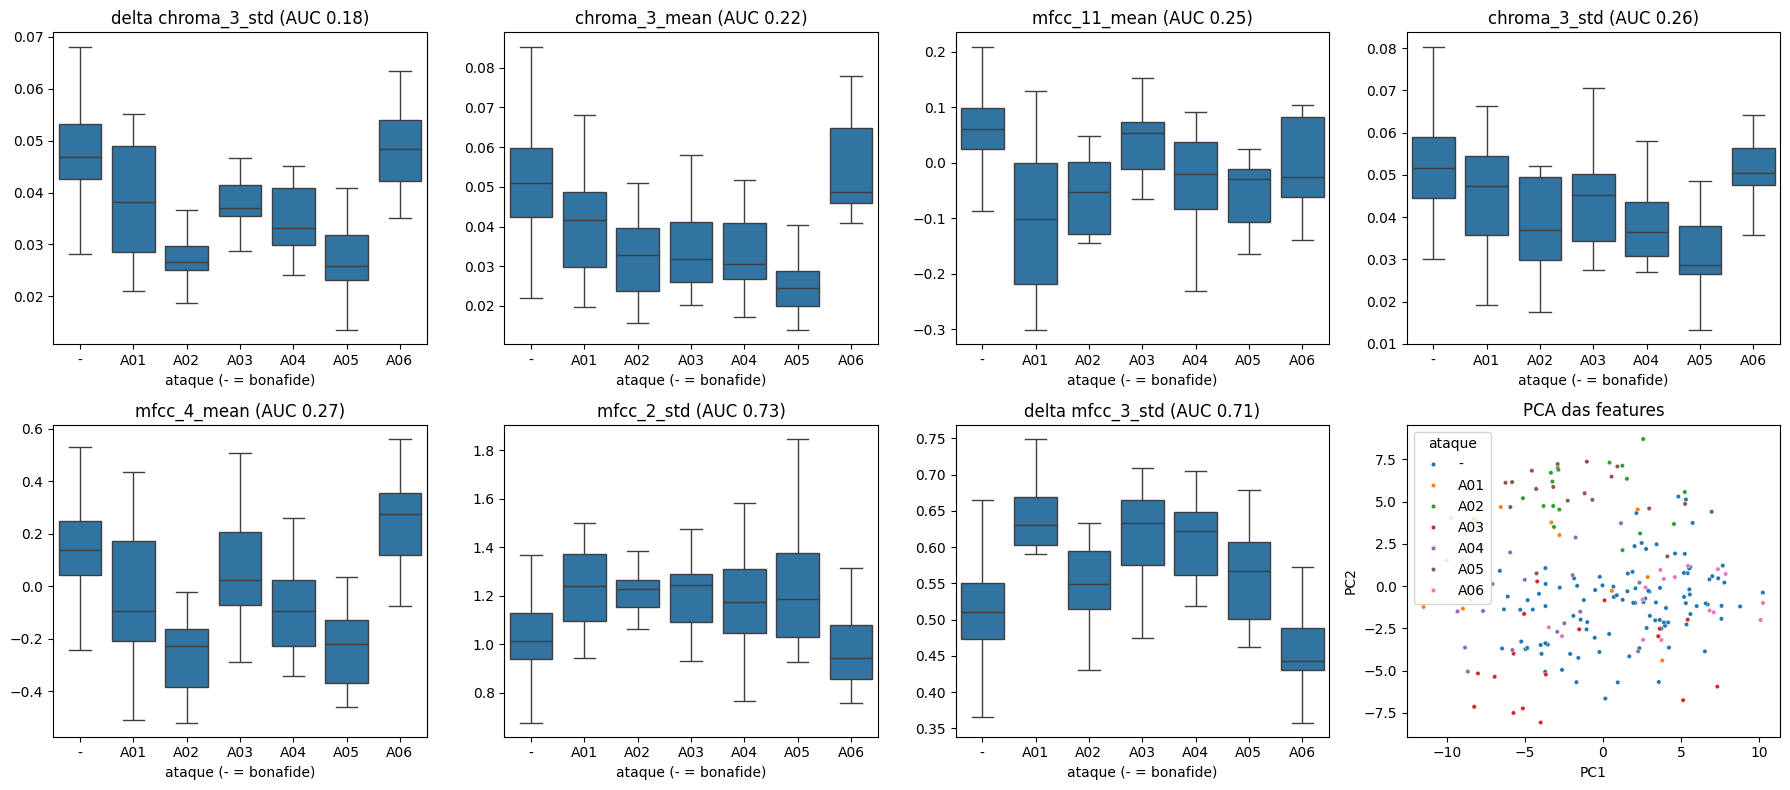

In [22]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

fig, eixos = plt.subplots(2, 4, figsize=(18, 8))
for feature, eixo in zip(ranking.index[:7], eixos.flat):
    sns.boxplot(data=dados, x="ataque", y=feature, ax=eixo, order=["-", *ATAQUES], showfliers=False)
    eixo.set(title=f"{feature} (AUC {auc_por_feature[feature]:.2f})", xlabel="ataque (- = bonafide)", ylabel="")

componentes = PCA(n_components=2, random_state=SEMENTE).fit_transform(StandardScaler().fit_transform(dados[COLUNAS_FEATURES]))
sns.scatterplot(x=componentes[:, 0], y=componentes[:, 1], hue=dados["ataque"], hue_order=["-", *ATAQUES], s=10, ax=eixos[1, 3])
eixos[1, 3].set(title="PCA das features", xlabel="PC1", ylabel="PC2")
fig.tight_layout()

**Análise.**
Nenhuma feature sozinha separa bem as classes: a melhor (`delta chroma_3_std`) tem AUC de 0,18, ou seja, 0,82 se invertida.
As mais discriminantes são de **chroma**, **MFCC** e **espalhamento espectral**, e a maioria tem valores menores para spoof, sugerindo que a fala gerada é espectralmente menos variável que a legítima.

Os *boxplots* e a PCA mostram que o comportamento depende muito do sistema de geração (Wang et al., 2020):

- **A02** (TTS) e **A05** (VC baseada em VAE) geram a forma de onda com o *vocoder* WORLD e são os mais diferentes da fala legítima, formando um grupo separado na PCA;
- **A06** (VC que ressintetiza com o **resíduo da fala original**) e, em parte, **A04** (TTS por concatenação de **fala real**) ficam sobrepostos à fala legítima em todas as features.

Ou seja, ataques que reaproveitam a fala real são os mais difíceis de detectar com features espectrais simples.
A duração total quase não separa as classes (AUC de 0,52), embora varie por ataque (mediana de 2,2 s para A01 contra 4,0 s para A02).
Com só 17 áudios por ataque, os *boxplots* por ataque são indicativos, não estimativas precisas.

## 6. Classificador: SVM

Separamos 25% do subconjunto para teste (estratificado por classe) e treinamos um SVM com todas as features, padronizadas.
O kernel (linear ou RBF) e o parâmetro de regularização `C` são escolhidos por `GridSearchCV`, com validação cruzada de 5 *folds* só no conjunto de treino, maximizando a AUC.
Além de acurácia, F1 e AUC, reportamos a **EER** (*Equal Error Rate*), métrica padrão do ASVspoof: a taxa de erro no limiar em que a taxa de falsos aceites (spoof aceito como bonafide) é igual à de falsas rejeições (bonafide rejeitado).

Melhor combinação: {'svc__C': 1, 'svc__kernel': 'rbf'} (AUC média na validação cruzada: 0.904)
Acurácia: 0.745
F1:       0.711
AUC:      0.865
EER:      0.235

              precision    recall  f1-score   support

    bonafide       0.71      0.85      0.77        26
       spoof       0.80      0.64      0.71        25

    accuracy                           0.75        51
   macro avg       0.75      0.74      0.74        51
weighted avg       0.75      0.75      0.74        51



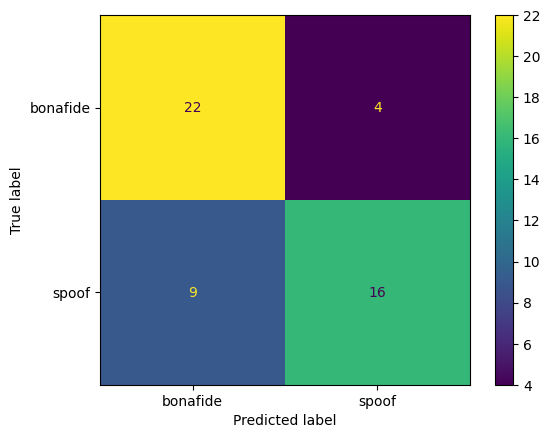

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score, roc_curve
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC


def calcular_eer(y_verdadeiro, score):
    fpr, tpr, _ = roc_curve(y_verdadeiro, score)
    fnr = 1 - tpr
    i = np.nanargmin(np.abs(fnr - fpr))
    return (fpr[i] + fnr[i]) / 2


X_treino, X_teste, y_treino, y_teste = train_test_split(
    dados[COLUNAS_FEATURES], y, test_size=0.25, stratify=y, random_state=SEMENTE
)
busca = GridSearchCV(
    make_pipeline(StandardScaler(), SVC()),
    {"svc__kernel": ["linear", "rbf"], "svc__C": [0.01, 0.1, 1, 10, 100]},
    scoring="roc_auc",
    cv=5,
).fit(X_treino, y_treino)
svm = busca.best_estimator_
score_teste = svm.decision_function(X_teste)
pred_teste = svm.predict(X_teste)

print(f"Melhor combinação: {busca.best_params_} (AUC média na validação cruzada: {busca.best_score_:.3f})")
print(f"Acurácia: {accuracy_score(y_teste, pred_teste):.3f}")
print(f"F1:       {f1_score(y_teste, pred_teste):.3f}")
print(f"AUC:      {roc_auc_score(y_teste, score_teste):.3f}")
print(f"EER:      {calcular_eer(y_teste, score_teste):.3f}\n")
print(classification_report(y_teste, pred_teste, target_names=["bonafide", "spoof"]))
ConfusionMatrixDisplay.from_predictions(y_teste, pred_teste, display_labels=["bonafide", "spoof"]);

**Análise.**
O `GridSearchCV` escolheu o kernel RBF com `C = 1` (AUC média de 0,904 na validação cruzada do treino).
No teste, o SVM acerta 75% dos áudios, com AUC de 0,865 e EER de 0,235.
Os erros se concentram em spoof classificado como bonafide (recall de 0,64 para spoof contra 0,85 para bonafide): 7 dos 9 spoof não detectados são do ataque **A06**, que o modelo não detectou nenhuma vez, o que é coerente com a análise exploratória.
Como o teste tem só 51 áudios, cada erro muda a acurácia em cerca de 2 pontos, então esses números têm bastante variância.

## 7. Conclusões

- Features clássicas de áudio, extraídas com o pyAudioAnalysis e resumidas por média e desvio padrão, permitem a um SVM separar fala legítima de fala gerada com 75% de acurácia e EER de 0,235 neste subconjunto de 204 áudios.
- Nenhuma feature sozinha basta (a melhor tem AUC de 0,82); as mais úteis são de chroma e MFCC, e a duração total quase não ajuda.
- A dificuldade varia muito entre ataques: alguns sistemas que sintetizam a forma de onda do zero (A02, A05) são fáceis de separar, enquanto os que reaproveitam a fala real se confundem com a fala legítima; o A06 não foi detectado nenhuma vez no teste.
- Do ponto de vista adversarial, um atacante que conheça o detector tenderia a escolher técnicas que preservam características da fala real, justamente as mais difíceis para estas features.

## Referências

- Wang, X. et al. (2020). ASVspoof 2019: A large-scale public database of synthesized, converted and replayed speech. *Computer Speech & Language*, 64, 101114. arXiv:1911.01601.
- Müller, N. M., Dieckmann, F., Czempin, P., Canals, R., Böttinger, K. & Williams, J. (2021). Speech is Silver, Silence is Golden: What do ASVspoof-trained Models Really Learn? *ASVspoof 2021 Workshop*. arXiv:2106.12914.
- Giannakopoulos, T. (2015). pyAudioAnalysis: An Open-Source Python Library for Audio Signal Analysis. *PLoS ONE*, 10(12), e0144610.
- Dataset no Kaggle: [awsaf49/asvpoof-2019-dataset](https://www.kaggle.com/datasets/awsaf49/asvpoof-2019-dataset).